### CUSTOMER CHURN PREDICTION

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
df = pd.read_csv(r"C:\Users\Windows\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")         #Telco Customer Churn 
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [76]:
df.shape

(7043, 21)

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [78]:
df.isnull().sum()              #Checking Missing Values

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')   #TotalCharges sometimes contains blank values so that must be converted to numeric
df = df.dropna()                 

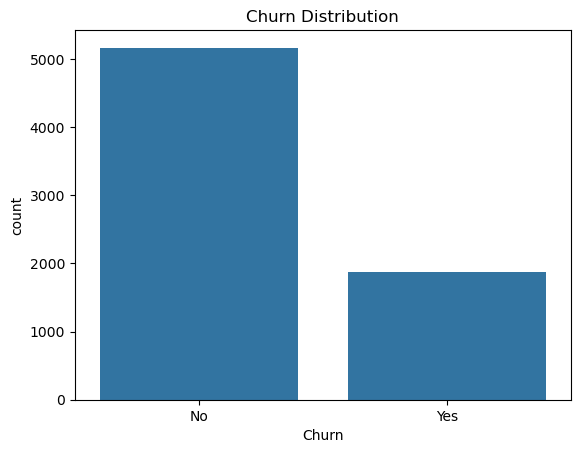

In [80]:
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

In [81]:
df = df.drop("customerID", axis=1)          #since not useful for prediction

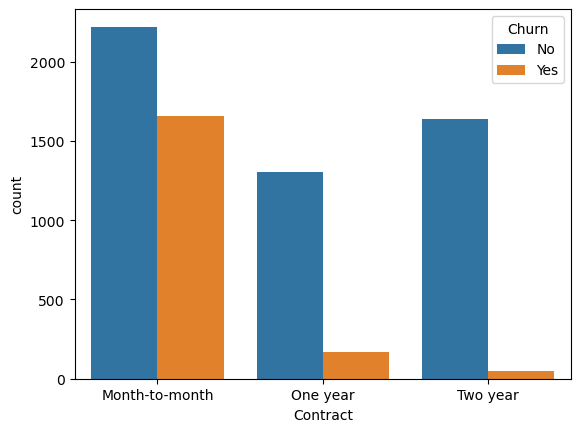

In [82]:
sns.countplot(x='Contract', hue='Churn', data=df)         #contract vs churn
plt.show()

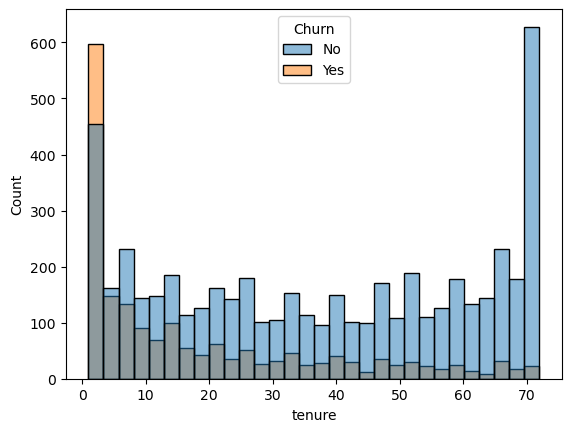

In [83]:
sns.histplot(data=df, x='tenure', hue='Churn', bins=30)     #Tenure vs Churn
plt.show()

In [84]:
le = LabelEncoder()                              #converting categorical data
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

In [85]:
X = df.drop("Churn", axis=1)                   #Feature Selection (Seperating input and target)
y = df["Churn"]

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)     #Train-Test Split

In [87]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [88]:
log_model = LogisticRegression(max_iter=1000)      #Training ML Model(Logistic Regression)
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)
print("Logistic Regression Accuracy:",accuracy_score(y_test, log_pred))

Logistic Regression Accuracy: 0.7874911158493249


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [89]:
dt_model = DecisionTreeClassifier()     #Training ML Model(Decision Tree)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.7306325515280739


In [90]:
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)      #Training ML Model(Random Forest)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.7924662402274343


In [91]:
results = pd.DataFrame({                                                      #Comparing Models
    'Model': ['Logistic Regression',
              'Decision Tree',
              'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ]
})
print(results)

                 Model  Accuracy
0  Logistic Regression  0.787491
1        Decision Tree  0.730633
2        Random Forest  0.792466


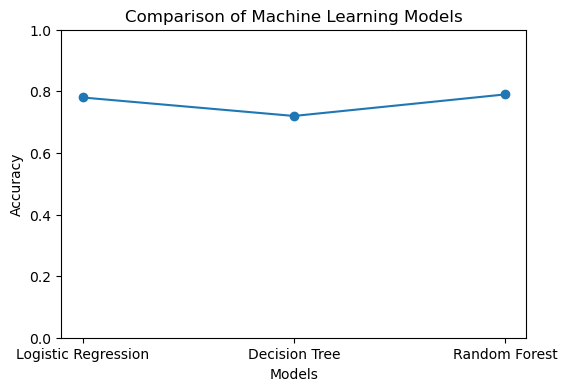

In [92]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Decision Tree', 'Random Forest']
accuracy = [0.78, 0.72, 0.79]   # replace with your actual accuracies

plt.figure(figsize=(6,4))
plt.plot(models, accuracy, marker='o', linestyle='-')

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0,1)

plt.show()

In [93]:
from sklearn.metrics import confusion_matrix     #confusion matrix for best model
confusion_matrix(y_test, rf_pred)

array([[932, 101],
       [191, 183]], dtype=int64)

In [94]:
from sklearn.ensemble import RandomForestClassifier                     #To know important features affecting using random forest classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
importance = rf.feature_importances_
features = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)
print(features.head(10))

            Feature  Importance
18     TotalCharges    0.184953
17   MonthlyCharges    0.178014
4            tenure    0.154510
14         Contract    0.080585
16    PaymentMethod    0.052031
8    OnlineSecurity    0.048509
11      TechSupport    0.047581
7   InternetService    0.026813
0            gender    0.026715
9      OnlineBackup    0.025883


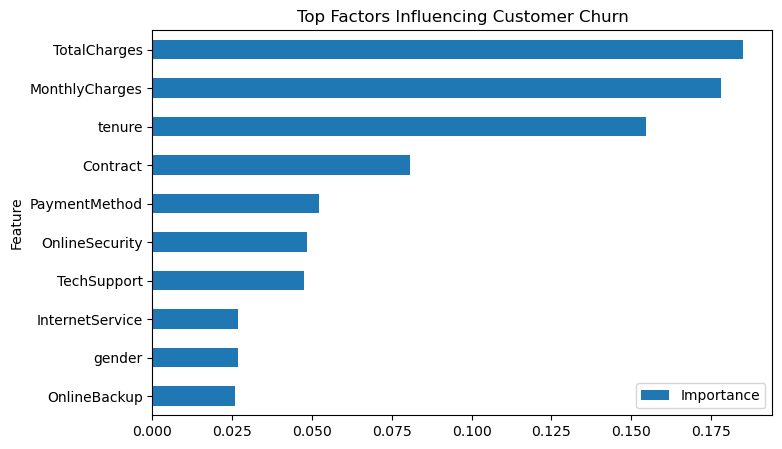

In [95]:
import matplotlib.pyplot as plt
features.head(10).plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(8,5)
)
plt.title("Top Factors Influencing Customer Churn")
plt.gca().invert_yaxis()
plt.show()

In [96]:
sample_customer = X_test.iloc[0].values.reshape(1,-1)               #Example churn prediction( 1= customer will churn; 0=customet will stay)
prediction = log_model.predict(sample_customer)
print(prediction)

[0]


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [97]:
probability = rf.predict_proba(sample_customer)

print(probability)

[[1. 0.]]


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [98]:
churn_probability = probability[0][1]

if churn_probability >= 0.75:
    risk = "High Risk"

elif churn_probability >= 0.40:
    risk = "Medium Risk"

else:
    risk = "Low Risk"

print("Risk Level:", risk)

Risk Level: Low Risk


In [99]:
sample_customer = X_test.iloc[0]
customer_data = sample_customer.to_dict()

print(customer_data)

{'gender': 1.0, 'SeniorCitizen': 1.0, 'Partner': 1.0, 'Dependents': 0.0, 'tenure': 61.0, 'PhoneService': 1.0, 'MultipleLines': 2.0, 'InternetService': 2.0, 'OnlineSecurity': 1.0, 'OnlineBackup': 1.0, 'DeviceProtection': 1.0, 'TechSupport': 1.0, 'StreamingTV': 1.0, 'StreamingMovies': 1.0, 'Contract': 2.0, 'PaperlessBilling': 0.0, 'PaymentMethod': 0.0, 'MonthlyCharges': 25.0, 'TotalCharges': 1501.75}


In [100]:
churn_probability = rf.predict_proba([sample_customer])[0][1]
churn_percentage = churn_probability * 100

if churn_probability >= 0.75:
    risk_level = "High Risk"
elif churn_probability >= 0.40:
    risk_level = "Medium Risk"
else:
    risk_level = "Low Risk"

print("Churn Probability:", churn_percentage)
print("Risk Level:", risk_level)

Churn Probability: 0.0
Risk Level: Low Risk


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [101]:
!pip install -U google-genai python-dotenv

Defaulting to user installation because normal site-packages is not writeable


In [102]:
# =========================================================
# STEP 2 — IMPORT LIBRARIES
# =========================================================

from google import genai
from dotenv import load_dotenv
import os

In [103]:
# =========================================================
# STEP 3 — LOAD GEMINI API KEY
# =========================================================

load_dotenv()

client = genai.Client(
    api_key=os.getenv("GEMINI_API_KEY")
)

In [104]:
# =========================================================
# STEP 4 — TAKE SAMPLE CUSTOMER
# =========================================================

sample_customer = X_test.iloc[0]

print(sample_customer)

gender                 1.00
SeniorCitizen          1.00
Partner                1.00
Dependents             0.00
tenure                61.00
PhoneService           1.00
MultipleLines          2.00
InternetService        2.00
OnlineSecurity         1.00
OnlineBackup           1.00
DeviceProtection       1.00
TechSupport            1.00
StreamingTV            1.00
StreamingMovies        1.00
Contract               2.00
PaperlessBilling       0.00
PaymentMethod          0.00
MonthlyCharges        25.00
TotalCharges        1501.75
Name: 2481, dtype: float64


In [105]:
# =========================================================
# STEP 5 — CONVERT CUSTOMER DATA TO DICTIONARY
# =========================================================

customer_data = sample_customer.to_dict()

print(customer_data)

{'gender': 1.0, 'SeniorCitizen': 1.0, 'Partner': 1.0, 'Dependents': 0.0, 'tenure': 61.0, 'PhoneService': 1.0, 'MultipleLines': 2.0, 'InternetService': 2.0, 'OnlineSecurity': 1.0, 'OnlineBackup': 1.0, 'DeviceProtection': 1.0, 'TechSupport': 1.0, 'StreamingTV': 1.0, 'StreamingMovies': 1.0, 'Contract': 2.0, 'PaperlessBilling': 0.0, 'PaymentMethod': 0.0, 'MonthlyCharges': 25.0, 'TotalCharges': 1501.75}


In [106]:
# =========================================================
# STEP 6 — GET CHURN PROBABILITY
# =========================================================

churn_probability = rf.predict_proba([sample_customer])[0][1]

print(churn_probability)

0.0


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [107]:
# =========================================================
# STEP 7 — CONVERT TO PERCENTAGE
# =========================================================

churn_percentage = churn_probability * 100

print(churn_percentage)

0.0


In [108]:
# =========================================================
# STEP 8 — RISK SEGMENTATION
# =========================================================

if churn_probability >= 0.75:
    risk_level = "High Risk"

elif churn_probability >= 0.40:
    risk_level = "Medium Risk"

else:
    risk_level = "Low Risk"

print(risk_level)

Low Risk


In [109]:
# =========================================================
# STEP 9 — CREATE GENAI PROMPT
# =========================================================

prompt = f"""
You are an expert telecom customer retention analyst.

Analyze the following customer churn prediction result.

Customer details:
{customer_data}

Churn probability:
{churn_percentage:.2f}%

Risk level:
{risk_level}

Generate:

1. Churn Risk Summary
2. Main Reasons for Churn
3. Customer Behavior Analysis
4. Retention Recommendations
5. Final Business Action

Use simple and professional language.
"""

print(prompt)


You are an expert telecom customer retention analyst.

Analyze the following customer churn prediction result.

Customer details:
{'gender': 1.0, 'SeniorCitizen': 1.0, 'Partner': 1.0, 'Dependents': 0.0, 'tenure': 61.0, 'PhoneService': 1.0, 'MultipleLines': 2.0, 'InternetService': 2.0, 'OnlineSecurity': 1.0, 'OnlineBackup': 1.0, 'DeviceProtection': 1.0, 'TechSupport': 1.0, 'StreamingTV': 1.0, 'StreamingMovies': 1.0, 'Contract': 2.0, 'PaperlessBilling': 0.0, 'PaymentMethod': 0.0, 'MonthlyCharges': 25.0, 'TotalCharges': 1501.75}

Churn probability:
0.00%

Risk level:
Low Risk

Generate:

1. Churn Risk Summary
2. Main Reasons for Churn
3. Customer Behavior Analysis
4. Retention Recommendations
5. Final Business Action

Use simple and professional language.



In [110]:
# =========================================================
# STEP 10 — SEND PROMPT TO GEMINI
# =========================================================

response = client.models.generate_content(
    model="gemini-3.5-flash",
    contents=prompt
)

In [111]:
# =========================================================
# STEP 11 — PRINT GENAI OUTPUT
# =========================================================

print(response.text)

Here is the expert retention analysis for the customer based on the provided data.

---

### 1. Churn Risk Summary
* **Churn Probability:** 0.00%
* **Risk Level:** Low Risk (High-Value / Ultra-Loyal)

This customer is an exemplary, highly stable, and low-risk account. With a tenure of 61 months (approximately 5 years) and a 2-year contract, this customer has demonstrated long-term brand loyalty. There is currently no active threat of churn.

---

### 2. Key Mitigating Factors (Why Churn Risk is 0.00%)
While the prompt asks for "Main Reasons for Churn," this customer has a 0% risk. Therefore, we highlight the factors actively *preventing* churn:
* **Long-Term Contract Commitment:** The customer is on a 2-Year Contract (Contract: 2.0), which is the strongest deterrent to churn.
* **Maximum Product Stickiness:** They subscribe to almost every available add-on service, including Phone Service (Multiple Lines), Internet, Online Security, Online Backup, Device Protection, Tech Support, Strea

In [112]:
# =========================================================
# STEP 12 — STORE OUTPUT
# =========================================================

genai_output = response.text

In [113]:
# =========================================================
# STEP 13 — PRINT STORED OUTPUT
# =========================================================

print(genai_output)

Here is the expert retention analysis for the customer based on the provided data.

---

### 1. Churn Risk Summary
* **Churn Probability:** 0.00%
* **Risk Level:** Low Risk (High-Value / Ultra-Loyal)

This customer is an exemplary, highly stable, and low-risk account. With a tenure of 61 months (approximately 5 years) and a 2-year contract, this customer has demonstrated long-term brand loyalty. There is currently no active threat of churn.

---

### 2. Key Mitigating Factors (Why Churn Risk is 0.00%)
While the prompt asks for "Main Reasons for Churn," this customer has a 0% risk. Therefore, we highlight the factors actively *preventing* churn:
* **Long-Term Contract Commitment:** The customer is on a 2-Year Contract (Contract: 2.0), which is the strongest deterrent to churn.
* **Maximum Product Stickiness:** They subscribe to almost every available add-on service, including Phone Service (Multiple Lines), Internet, Online Security, Online Backup, Device Protection, Tech Support, Strea

In [114]:
# =========================================================
# STEP 14 — CREATE REUSABLE FUNCTION
# =========================================================

def generate_churn_explanation(customer_data,
                               churn_percentage,
                               risk_level):

    prompt = f"""
You are an expert telecom customer retention analyst.

Analyze the following customer churn prediction result.

Customer details:
{customer_data}

Churn probability:
{churn_percentage:.2f}%

Risk level:
{risk_level}

Generate:

1. Churn Risk Summary
2. Main Reasons for Churn
3. Customer Behavior Analysis
4. Retention Recommendations
5. Final Business Action

Use simple and professional language.
"""

    response = client.models.generate_content(
        model="gemini-3.5-flash",
        contents=prompt
    )

    return response.text

In [115]:
# =========================================================
# STEP 15 — TEST FUNCTION
# =========================================================

explanation = generate_churn_explanation(
    customer_data,
    churn_percentage,
    risk_level
)

print(explanation)

Based on the provided customer data and predictive analytics, here is the retention analysis for this customer.

---

### 1. Churn Risk Summary
*   **Churn Probability:** 0.00%
*   **Risk Level:** Low Risk (Ultra-Low)
*   **Status Overview:** This customer is an exemplary highly loyal, low-maintenance subscriber. With a tenure of 61 months (over 5 years) and a long-term contract, there is currently zero statistical probability of churn. 

---

### 2. Main Reasons for Churn (Risk Factor Assessment)
While the overall churn risk is **0.00%**, we analyze potential long-term vulnerability factors vs. stabilizing factors:
*   **Stabilizing Factors (Why they won’t churn):**
    *   **Two-Year Contract:** The customer is on a highly stable 2-year contract, which is the strongest deterrent to churn.
    *   **High Tenure:** 61 months of continuous service indicates strong brand loyalty and habituation.
    *   **Low Monthly Spend:** At $25.00/month, the service is highly affordable, making the 

In [116]:
# =========================================================
# STEP 16 — RETENTION RECOMMENDATION ENGINE
# =========================================================

def retention_recommendation(row):

    recommendations = []

    if row["tenure"] < 12:
        recommendations.append(
            "Offer loyalty bonus for new customers."
        )

    if row["MonthlyCharges"] > 70:
        recommendations.append(
            "Provide discount or lower pricing plan."
        )

    if row["Contract"] == 0:
        recommendations.append(
            "Encourage yearly contract subscription."
        )

    if row["TechSupport"] == 0:
        recommendations.append(
            "Offer free technical support trial."
        )

    return recommendations

In [117]:
# =========================================================
# STEP 17 — TEST RECOMMENDATIONS
# =========================================================

recommendations = retention_recommendation(sample_customer)

print(recommendations)

[]


In [118]:
# =========================================================
# STEP 18 — FINAL OUTPUT
# =========================================================

print("Churn Probability:", churn_percentage)

print("\nRisk Level:")
print(risk_level)

print("\nAI Explanation:")
print(explanation)

print("\nRetention Recommendations:")
print(recommendations)

Churn Probability: 0.0

Risk Level:
Low Risk

AI Explanation:
Based on the provided customer data and predictive analytics, here is the retention analysis for this customer.

---

### 1. Churn Risk Summary
*   **Churn Probability:** 0.00%
*   **Risk Level:** Low Risk (Ultra-Low)
*   **Status Overview:** This customer is an exemplary highly loyal, low-maintenance subscriber. With a tenure of 61 months (over 5 years) and a long-term contract, there is currently zero statistical probability of churn. 

---

### 2. Main Reasons for Churn (Risk Factor Assessment)
While the overall churn risk is **0.00%**, we analyze potential long-term vulnerability factors vs. stabilizing factors:
*   **Stabilizing Factors (Why they won’t churn):**
    *   **Two-Year Contract:** The customer is on a highly stable 2-year contract, which is the strongest deterrent to churn.
    *   **High Tenure:** 61 months of continuous service indicates strong brand loyalty and habituation.
    *   **Low Monthly Spend:** 

In [119]:
results = X_test.copy()

results["Actual_Churn"] = y_test.values

results["Predicted_Churn"] = rf_model.predict(X_test)

results["Churn_Probability"] = rf_model.predict_proba(X_test)[:, 1]

results["Risk_Level"] = results["Churn_Probability"].apply(
    lambda x:
    "High Risk" if x >= 0.75
    else "Medium Risk" if x >= 0.40
    else "Low Risk"
)

results.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
2481,1,1,1,0,61,1,2,2,1,1,...,1,2,0,0,25.00,1501.75,0,0,0.00,Low Risk
6784,0,0,0,0,19,1,2,2,1,1,...,1,0,0,0,24.70,465.85,0,0,0.10,Low Risk
6125,1,0,1,0,13,1,2,1,0,0,...,2,0,1,1,102.25,1359.00,1,1,0.75,High Risk
3052,1,0,1,0,37,1,2,0,2,0,...,0,0,1,3,55.05,2030.75,0,0,0.21,Low Risk
4099,0,0,0,0,6,0,1,0,2,0,...,0,0,0,0,29.45,161.45,0,0,0.24,Low Risk


In [120]:
import sqlite3

In [121]:
conn = sqlite3.connect("churn_database.db")

In [122]:
results.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

1407

In [123]:
query = "SELECT * FROM customers LIMIT 5"

pd.read_sql(query, conn)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
0,1,1,1,0,61,1,2,2,1,1,...,1,2,0,0,25.00,1501.75,0,0,0.00,Low Risk
1,0,0,0,0,19,1,2,2,1,1,...,1,0,0,0,24.70,465.85,0,0,0.10,Low Risk
2,1,0,1,0,13,1,2,1,0,0,...,2,0,1,1,102.25,1359.00,1,1,0.75,High Risk
3,1,0,1,0,37,1,2,0,2,0,...,0,0,1,3,55.05,2030.75,0,0,0.21,Low Risk
4,0,0,0,0,6,0,1,0,2,0,...,0,0,0,0,29.45,161.45,0,0,0.24,Low Risk


In [124]:
!pip install langchain langchain-community

Defaulting to user installation because normal site-packages is not writeable
  Using cached httpx_sse-0.4.3-py3-none-any.whl.metadata (9.7 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ----------------- ---------------------- 1.0/2.4 MB 2.5 MB/s eta 0:00:01
   ------------------------------- -------- 1.8/2.4 MB 3.0 MB/s eta 0:00:01
   ---------------------------------------  2.4/2.4 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 2.4 MB/s eta 0:00:00
Using cached httpx_sse-0.4.3-py3-none-any.whl (9.0 kB)
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 5.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/548.1 kB ? eta -:--:--
   -------------------------------------- - 524.3/548.1 kB 2.8 MB/s eta 0:00:01
   -------------------------------------- - 524.3/548.1 kB 2.8 

In [125]:
from langchain_community.utilities import SQLDatabase

C:\Users\Windows\AppData\Local\Temp\ipykernel_7124\1266060898.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


In [126]:
db = SQLDatabase.from_uri(
    "sqlite:///churn_database.db"
)

In [127]:
print(db.get_usable_table_names())

['customers']


In [135]:
def generate_sql_query(user_question):

    sql_prompt = f"""
You are an expert SQL analyst.

Database table name:
customers

The table contains:
- tenure
- MonthlyCharges
- Contract
- TechSupport
- Churn_Probability
- Risk_Level
- Predicted_Churn

Convert the following English question into SQL query.

Question:
{user_question}

Only return SQL query.
Do not return markdown.
Do not use ```sql.
"""

    response = client.models.generate_content(
        model="gemini-3.5-flash",
        contents=sql_prompt
    )

    sql_query = response.text.strip()

    sql_query = sql_query.replace("```sql", "")
    sql_query = sql_query.replace("```", "")

    return sql_query.strip()

In [136]:
question = "Show all high risk customers"

sql_query = generate_sql_query(question)

print(sql_query)

SELECT * FROM customers WHERE Risk_Level = 'High'


In [137]:
query_result = pd.read_sql(
    sql_query,
    conn
)

query_result.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level


In [138]:
query = "SELECT * FROM customers"

full_data = pd.read_sql(query, conn)

print(full_data)

      gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0          1              1        1           0      61             1   
1          0              0        0           0      19             1   
2          1              0        1           0      13             1   
3          1              0        1           0      37             1   
4          0              0        0           0       6             0   
...      ...            ...      ...         ...     ...           ...   
1402       1              0        0           0       1             1   
1403       1              0        0           0      12             1   
1404       0              0        0           0      26             1   
1405       0              1        0           0      35             1   
1406       0              0        1           1      72             1   

      MultipleLines  InternetService  OnlineSecurity  OnlineBackup  ...  \
0                 2                2

In [139]:
full_data.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

1407

In [140]:
!pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
